# Classificador de documentos — experimento (versão VS Code)

**Disciplina:** Sistemas Inteligentes  
**Objetivo:** validar os dados e comparar KNN, Árvore de Decisão e Random Forest.

Este notebook faz **exatamente o mesmo experimento** do notebook do Colab
(`Classificador_Documentos_Integrado_Colab.ipynb`, que está nesta pasta sem alterações),
mas o código agora vive em módulos reutilizáveis dentro do pacote `classificador/`.
Cada célula abaixo só **chama** esses módulos e mostra o resultado.

| Seção | Módulo responsável |
|---|---|
| 2. Dataset | `classificador/dados/gerador.py` |
| 3. Validação | `classificador/dados/validacao.py` |
| 4. Treino/teste | `classificador/dados/divisao.py` |
| 5. Treinamento | `classificador/modelos/` |
| 6–7. Métricas e gráficos | `classificador/avaliacao/` |
| 8. Salvar | `classificador/persistencia.py` |
| 9.1. Imagem real (OCR) | `classificador/extracao/imagem.py` |
| 10. Compatibilidade | `classificador/verificacao.py` |
| Melhor modelo | `classificador/avaliacao/selecao.py` + `classificador/exportacao.py` |

> **Limitação:** o conjunto é sintético/fictício. As métricas não comprovam desempenho em
> passaportes reais. Algumas características refletem os padrões usados para gerar os
> exemplos e podem tornar a classificação artificialmente fácil.

## 1. Preparar o ambiente
No VS Code, selecione o kernel do `.venv` do projeto (canto superior direito).

In [1]:
import sys
from pathlib import Path

# Garante que a raiz do projeto está no caminho de importação (o notebook fica em notebooks/).
RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import pandas as pd
from IPython.display import display

from classificador.avaliacao import (
    avaliar_modelos, escolher_melhor_modelo, plotar_comparacao,
    plotar_matriz_confusao, relatorio_classificacao,
)
from classificador.config import (
    COLUNA_ALVO, CSV_FEATURES, DIR_MELHOR_MODELO, DIR_RESULTADOS, SEED,
)
from classificador.dados import (
    contar_ausentes, contar_por_classe, dividir_treino_teste, gerar_dataset,
    selecionar_features, validar_dataset,
)
from classificador.exportacao import exportar_melhor_modelo
from classificador.extracao import extrair_features_de_imagem
from classificador.modelos import criar_modelos, treinar_modelos
from classificador.persistencia import nome_arquivo_seguro, salvar_dataset, salvar_resultados
from classificador.verificacao import verificar_compatibilidade

print("Raiz do projeto:", RAIZ.name)

Raiz do projeto: classificador-documentos


## 2. Gerar o dataset sintético
Com `SEED = 42` o dataset é idêntico ao do Colab. O CSV é gravado em `data/features_passaportes.csv`.

In [2]:
df = gerar_dataset(SEED)
salvar_dataset(df, CSV_FEATURES)
print(f"Dataset gerado: {df.shape[0]} linhas × {df.shape[1]} colunas")
display(df.sample(5, random_state=SEED))

Dataset gerado: 300 linhas × 25 colunas


,nome_arquivo,caminho_arquivo,x_face,y_face,w_face,h_face,quantidade_palavras,presenca_qrcode,presenca_rostos,qtd_cnh,...,qtd_passaporte,qtd_validade,qtd_nacional,qtd_estudante,qtd_matricula,qtd_universidade,qtd_estadual,qtd_une,label,texto_ocr
203,invalido_004.png,dataset/invalido/invalido_004.png,0.0,0.0,0.0,0.0,29.0,0,0,0,...,0,0,0,1,0,0,0,0,invalido,STUDENT_CARD
266,invalido_067.png,dataset/invalido/invalido_067.png,20.0,19.0,NaN,44.0,20.0,0,1,0,...,0,0,0,2,0,0,0,0,invalido,STUDENT_CARD
152,estrangeiro_053.png,dataset/estrangeiro/estrangeiro_053.png,0.0,0.0,0.0,0.0,19.0,1,0,0,...,0,1,0,0,0,0,0,0,estrangeiro,FOREIGN_PASSPORT
9,brasileiro_010.png,dataset/brasileiro/brasileiro_010.png,NaN,26.0,93.0,92.0,18.0,0,1,0,...,1,1,1,0,0,0,0,0,brasileiro,PASSPORT
233,invalido_034.png,dataset/invalido/invalido_034.png,0.0,0.0,0.0,0.0,19.0,0,0,0,...,0,0,0,2,0,0,0,0,invalido,STUDENT_CARD


In [3]:
# Amostra balanceada (5 de cada classe), com todas as colunas visíveis.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

amostra = pd.concat([
    df[df[COLUNA_ALVO] == classe].sample(5, random_state=SEED)
    for classe in ("brasileiro", "estrangeiro", "invalido")
])
print(f"Amostra de {len(amostra)} linhas:")
display(amostra)

Amostra de 15 linhas:


,nome_arquivo,caminho_arquivo,x_face,y_face,w_face,h_face,quantidade_palavras,presenca_qrcode,presenca_rostos,qtd_cnh,qtd_rg,qtd_detran,qtd_cpf,qtd_documento,qtd_identidade,qtd_passaporte,qtd_validade,qtd_nacional,qtd_estudante,qtd_matricula,qtd_universidade,qtd_estadual,qtd_une,label,texto_ocr
83,brasileiro_084.png,dataset/brasileiro/brasileiro_084.png,20.0,NaN,73.0,119.0,25.0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,brasileiro,PASSPORT
53,brasileiro_054.png,dataset/brasileiro/brasileiro_054.png,15.0,58.0,104.0,91.0,24.0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,brasileiro,PASSPORT
70,brasileiro_071.png,dataset/brasileiro/brasileiro_071.png,39.0,57.0,122.0,107.0,24.0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,brasileiro,PASSPORT
45,brasileiro_046.png,dataset/brasileiro/brasileiro_046.png,39.0,31.0,121.0,72.0,22.0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,brasileiro,PASSPORT
44,brasileiro_045.png,dataset/brasileiro/brasileiro_045.png,45.0,NaN,83.0,82.0,25.0,0,1,0,0,0,0,0,0,1,1,1,0,0,0,0,0,brasileiro,PASSPORT
183,estrangeiro_084.png,dataset/estrangeiro/estrangeiro_084.png,0.0,0.0,0.0,0.0,14.0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,estrangeiro,FOREIGN_PASSPORT
153,estrangeiro_054.png,dataset/estrangeiro/estrangeiro_054.png,28.0,66.0,78.0,125.0,NaN,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,estrangeiro,FOREIGN_PASSPORT
170,estrangeiro_071.png,dataset/estrangeiro/estrangeiro_071.png,NaN,26.0,124.0,129.0,13.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,estrangeiro,FOREIGN_PASSPORT
145,estrangeiro_046.png,dataset/estrangeiro/estrangeiro_046.png,0.0,0.0,0.0,0.0,18.0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,estrangeiro,FOREIGN_PASSPORT
144,estrangeiro_045.png,dataset/estrangeiro/estrangeiro_045.png,NaN,59.0,126.0,82.0,15.0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,estrangeiro,FOREIGN_PASSPORT


## 3. Validar e entender os dados

`nome_arquivo`, `caminho_arquivo` e `texto_ocr` **não** são usados no treinamento.
`label` é a classe que queremos prever.

In [4]:
features = selecionar_features(df)

print("Quantidade por classe:")
display(contar_por_classe(df))
print("\nValores ausentes (serão resolvidos pelo Imputer):")
display(contar_ausentes(df))

validar_dataset(df, features)  # levanta ValueError se algo estiver errado
print("\nCaracterísticas numéricas em uso:", features)

Quantidade por classe:


,classe,quantidade
0,brasileiro,100
1,estrangeiro,100
2,invalido,100



Valores ausentes (serão resolvidos pelo Imputer):


,ausentes
x_face,37
y_face,36
w_face,37
h_face,27
quantidade_palavras,34



Características numéricas em uso: ['x_face', 'y_face', 'w_face', 'h_face', 'quantidade_palavras', 'presenca_qrcode', 'presenca_rostos', 'qtd_cnh', 'qtd_rg', 'qtd_detran', 'qtd_cpf', 'qtd_documento', 'qtd_identidade', 'qtd_passaporte', 'qtd_validade', 'qtd_nacional', 'qtd_estudante', 'qtd_matricula', 'qtd_universidade', 'qtd_estadual', 'qtd_une']


## 4. Separar treino e teste
A separação é estratificada para manter a proporção das três classes.

In [5]:
X_treino, X_teste, y_treino, y_teste = dividir_treino_teste(df, features)
print("Treino:", X_treino.shape, "| Teste:", X_teste.shape)

Treino: (225, 21) | Teste: (75, 21)


## 5. Treinar três classificadores

- **KNN:** usa os exemplos mais próximos; por isso inclui padronização.
- **Árvore de Decisão:** aprende regras em formato de árvore.
- **Random Forest:** combina várias árvores.

Os três são `Pipeline`s com imputação da mediana (definidos em `classificador/modelos/fabrica.py`).

In [6]:
modelos = treinar_modelos(criar_modelos(SEED), X_treino, y_treino)

Treinado com sucesso: KNN
Treinado com sucesso: Árvore de Decisão


Treinado com sucesso: Random Forest


## 6. Avaliar e comparar
Acurácia, precisão macro, recall macro e F1 macro, mais as matrizes de confusão.

In [7]:
classes = sorted(y_teste.unique())
metricas, predicoes = avaliar_modelos(modelos, X_teste, y_teste)
display(metricas.round(4))

,modelo,acuracia,precisao_macro,recall_macro,f1_macro
0,Árvore de Decisão,0.96,0.9605,0.96,0.9600
1,Random Forest,0.96,0.9643,0.96,0.9599
2,KNN,0.92,0.9274,0.92,0.9207



===== Relatório: KNN =====
              precision    recall  f1-score   support

  brasileiro       0.95      0.84      0.89        25
 estrangeiro       0.83      0.96      0.89        25
    invalido       1.00      0.96      0.98        25

    accuracy                           0.92        75
   macro avg       0.93      0.92      0.92        75
weighted avg       0.93      0.92      0.92        75



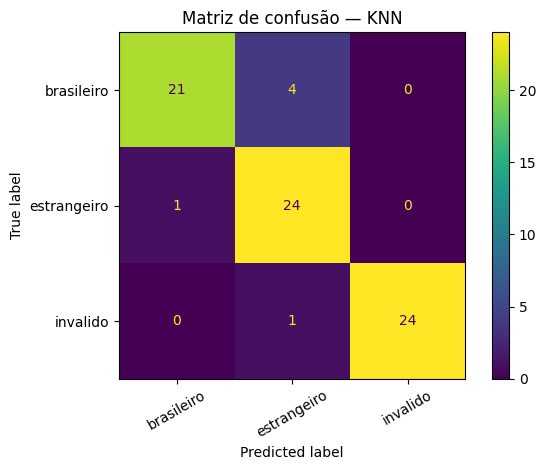


===== Relatório: Árvore de Decisão =====
              precision    recall  f1-score   support

  brasileiro       0.96      0.92      0.94        25
 estrangeiro       0.92      0.96      0.94        25
    invalido       1.00      1.00      1.00        25

    accuracy                           0.96        75
   macro avg       0.96      0.96      0.96        75
weighted avg       0.96      0.96      0.96        75



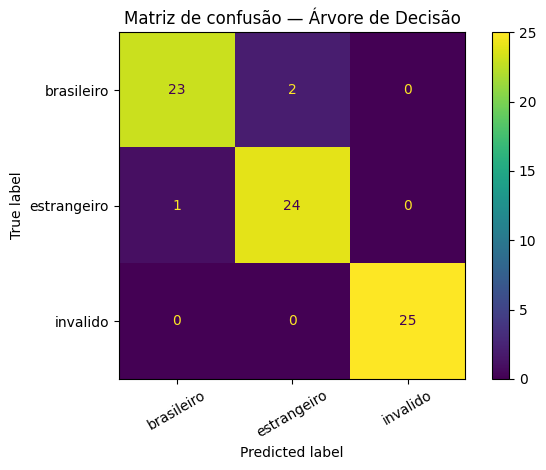


===== Relatório: Random Forest =====
              precision    recall  f1-score   support

  brasileiro       1.00      0.88      0.94        25
 estrangeiro       0.89      1.00      0.94        25
    invalido       1.00      1.00      1.00        25

    accuracy                           0.96        75
   macro avg       0.96      0.96      0.96        75
weighted avg       0.96      0.96      0.96        75



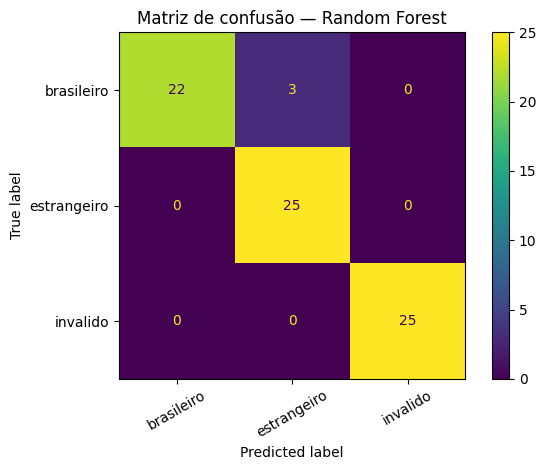

In [8]:
for nome, pred in predicoes.items():
    print(f"\n===== Relatório: {nome} =====")
    print(relatorio_classificacao(y_teste, pred))
    plotar_matriz_confusao(y_teste, pred, classes, nome, mostrar=True)

### 6.1. Escolha do melhor modelo

A tabela acima mostra **Árvore de Decisão (F1 0,9600)** e **Random Forest (F1 0,9599)** praticamente
empatadas. Com 75 exemplos de teste, um único exemplo já vale ~1,3 ponto percentual, então essa diferença
de 0,0001 não significa nada.

O critério do projeto (`classificador/avaliacao/selecao.py`) é:

1. ordenar pelo F1 macro no teste;
2. considerar **empatados** os modelos a menos de 1 exemplo de teste do primeiro;
3. desempatar pela **validação cruzada nos dados de treino** (o teste não é usado nisso).

In [9]:
selecao = escolher_melhor_modelo(
    metricas, modelos, X_treino, y_treino, n_teste=len(X_teste), seed=SEED
)
display(selecao.finalistas.round(4))
print(selecao.justificativa)
print("\nMELHOR MODELO:", selecao.melhor)

,modelo,f1_macro_teste,f1_macro_cv_media,f1_macro_cv_desvio
0,Random Forest,0.9599,0.9786,0.0213
1,Árvore de Decisão,0.9600,0.9492,0.0293


Empate técnico no teste entre: Random Forest, Árvore de Decisão (diferença de F1 macro menor que 1 exemplo de teste = 0.0133). Desempate por validação cruzada 5-fold x 5 repetições nos dados de treino: Random Forest obteve a maior média de F1 macro (0.9786).

MELHOR MODELO: Random Forest


## 7. Gráfico comparativo

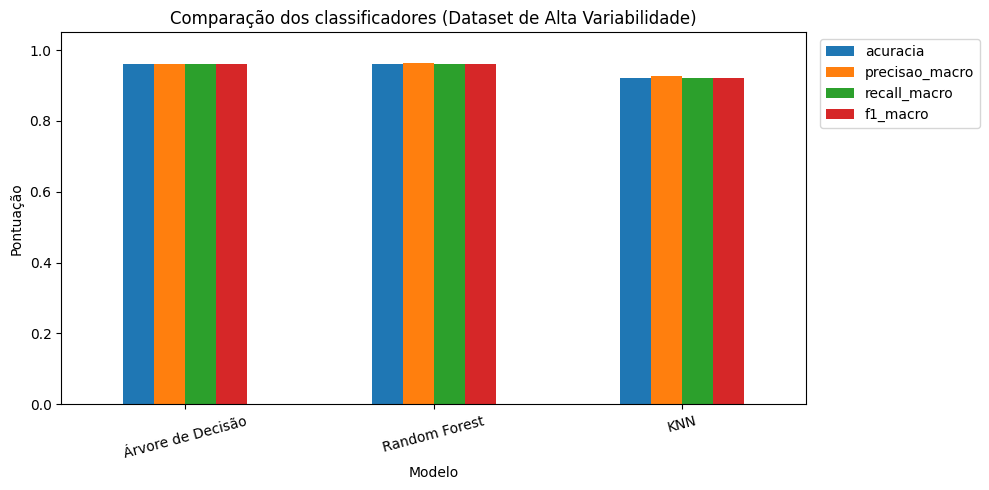

In [10]:
plotar_comparacao(metricas, mostrar=True)

## 8. Salvar resultados e modelos
Grava em `resultados/`: métricas, dataset usado, os 3 modelos (`.joblib`) e as matrizes de confusão.

In [11]:
arquivos = salvar_resultados(
    DIR_RESULTADOS, df, metricas, modelos, predicoes, y_teste, features, classes
)
print("Resultados salvos em:", DIR_RESULTADOS.relative_to(RAIZ))
for arquivo in arquivos:
    print("-", arquivo.name)

Resultados salvos em: resultados
- arvore_de_decisao.joblib
- comparacao_modelos.csv
- dataset_utilizado.csv
- knn.joblib
- matriz_confusao_arvore_de_decisao.csv
- matriz_confusao_knn.csv
- matriz_confusao_random_forest.csv
- random_forest.joblib


## 9. Demonstração de previsão
Usa uma linha já existente no dataset apenas para demonstrar a chamada; **não** é uma avaliação independente.

In [12]:
melhor = modelos[selecao.melhor]
exemplo = df[features].iloc[[0]]
print("Classe real:", df[COLUNA_ALVO].iloc[0])
print("Classe prevista:", melhor.predict(exemplo)[0])

Classe real: brasileiro
Classe prevista: brasileiro


## 9.1. Extração de características de imagens reais (visão computacional + OCR)

`extrair_features_de_imagem` recebe a imagem de um documento, detecta o rosto (OpenCV) e lê o texto (Tesseract),
gerando a mesma linha de 21 características que o modelo espera.

Requer o programa **Tesseract** instalado no sistema (veja o `README.md`). Para trocar o idioma do OCR,
defina a variável de ambiente `TESSERACT_LANG` (padrão: `por`).

A imagem abaixo é um exemplo **fictício** gerado só para a demonstração.

In [13]:
caminho_imagem_teste = DIR_MELHOR_MODELO / "exemplos" / "documento_exemplo_estudante.png"

try:
    features_imagem, texto_bruto = extrair_features_de_imagem(caminho_imagem_teste)

    print("--- Texto extraído via OCR ---")
    print(texto_bruto[:500])
    print("\n--- Características extraídas (apenas as diferentes de zero) ---")
    display(features_imagem.loc[:, (features_imagem != 0).any()])

    classe = melhor.predict(features_imagem)[0]
    print(f"\nResultado da predição para o documento: {classe.upper()}")
except (FileNotFoundError, ImportError, RuntimeError) as erro:
    print(f"Aviso: não foi possível processar a imagem. {erro}")

--- Texto extraído via OCR ---
CARTEIRA DE ESTUDANTE
UNIVERSIDADE ESTADUAL
MATRICULA 20231
DOCUMENTO VALIDO


--- Características extraídas (apenas as diferentes de zero) ---


,quantidade_palavras,qtd_documento,qtd_validade,qtd_estudante,qtd_matricula,qtd_universidade,qtd_estadual
0,9.0,1.0,1.0,2.0,1.0,1.0,1.0



Resultado da predição para o documento: INVALIDO


## 10. Verificar compatibilidade modelo ↔ extrator
Confere se o extrator gera exatamente as colunas (nomes e ordem) que o modelo salvo espera.

In [14]:
caminho_modelo_salvo = DIR_RESULTADOS / f"{nome_arquivo_seguro(selecao.melhor)}.joblib"
erros = verificar_compatibilidade(caminho_modelo_salvo)

OK: modelo carregado (21 características esperadas).
OK: o extrator gera as mesmas variáveis, na ordem correta.
OK: teste de sanidade do pipeline aprovado (classe simulada: 'estrangeiro').

OK: o pipeline de imagem real é compatível com o modelo treinado.


## 11. Exportar o melhor modelo para execução separada

Grava em `melhor_modelo/` o modelo escolhido, o extrator de imagens, os metadados, as dependências e
exemplos de teste. Essa pasta roda sozinha com `python melhor_modelo/predict.py --demo`.

In [15]:
linha_melhor = metricas[metricas["modelo"] == selecao.melhor].iloc[0].to_dict()
arquivos_melhor = exportar_melhor_modelo(
    selecao.melhor, melhor, features, classes, linha_melhor,
    selecao, X_treino, X_teste, y_teste, destino=DIR_MELHOR_MODELO,
)
for arquivo in arquivos_melhor:
    print("-", arquivo.relative_to(DIR_MELHOR_MODELO))

- modelo.joblib
- metadata.json
- requirements.txt
- exemplos/exemplos_teste.csv
- extrator_imagem.py


## 12. Conclusão e limitações

1. Foram comparados três algoritmos com a mesma divisão treino/teste.
2. As métricas descrevem somente este conjunto sintético.
3. Alguns campos, como face e QR Code, podem estar zerados por construção.
4. Para avançar, será necessário extrair características diretamente das imagens por um processo consistente
   (OCR e análise visual) e testar em imagens diferentes das usadas na geração.
5. O notebook não usa nome do arquivo, caminho da imagem ou texto OCR como atributos de treinamento.

**Não use este protótipo para decisões oficiais.**